# Experiment 7: Upscaling a Render Without Changing the Design

After a render is made, architects often want a **bigger, sharper version** for print or a client presentation. This is called **upscaling**: making an image larger (here 4×) while adding detail.

The risk is the same as in all my experiments: a strong upscaler can **invent details**. A bookshelf can get new objects, a painting a new pattern, a marble surface a new texture. For an architect, an invented detail is a design change.

**How I test it fairly.** I take a sharp interior photo as the **ground truth** (1280×768), shrink it 4× to 320×192, then let each method bring it back to 1280×768. Because I know what the real image looks like, I can measure how close each result is.

| Method | What it is |
|---|---|
| **A: Bicubic** | Classic resizing, no AI. Fast but blurry. The baseline. |
| **B: Real-ESRGAN** | A small GAN trained to sharpen and enlarge photos. Fast. |
| **C: SD x4 upscaler** | A diffusion model made for 4× upscaling. Adds detail, but can invent it. |
| **D: Real-ESRGAN + SD refine** | B, then a light Stable Diffusion img2img pass (strength 0.25) to add texture. A common "creative upscale" in render tools. |

**Metrics (against the ground truth):**

| Metric | What it tells | Better |
|---|---|---|
| **PSNR** | Pixel-level closeness | higher |
| **SSIM** | Structural similarity (0 to 1) | higher |
| **LPIPS** | Perceptual difference: how different it *looks* to a neural network trained to match human judgment | lower |
| **Mean ΔE** | Average color change (CIEDE2000) | lower |
| **Sharpness ratio** | Sharpness of the result divided by the sharpness of the ground truth (Laplacian variance). 1.0 = as sharp as the real image; above 1 = sharper than reality, often a sign of invented texture | close to 1 |
| **Sec/image, peak memory** | Cost on a free T4 GPU | lower |

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate spandrel lpips

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload sharp interior photos
Upload **3 to 5 interior photos**, ideally sharp and at least 1280 px wide (the same rooms as Experiment 6 work well). Each photo is center-cropped to 5:3 (no stretching) and resized to 1280×768: this is the ground truth.

In [3]:
import io, time, urllib.request
import numpy as np, pandas as pd, cv2
from PIL import Image
from IPython.display import Image as IPImage
from google.colab import files

GT_W, GT_H = 1280, 768
LR_W, LR_H = GT_W // 4, GT_H // 4

uploaded = files.upload()
images = sorted(uploaded)

def center_crop_5_3(img):
    w, h = img.size
    target = 5 / 3
    if w / h > target:
        nw = int(h * target); x = (w - nw) // 2; img = img.crop((x, 0, x + nw, h))
    else:
        nh = int(w / target); y = (h - nh) // 2; img = img.crop((0, y, w, y + nh))
    return img

gt, lr = {}, {}
for n, name in enumerate(images, start=1):
    img = center_crop_5_3(Image.open(name).convert("RGB")).resize((GT_W, GT_H), Image.LANCZOS)
    gt[n] = img
    lr[n] = img.resize((LR_W, LR_H), Image.BICUBIC)          # the small input every method gets
    print(f"room {n}: {name} → ground truth {img.size}, input {lr[n].size}")

def show(img, max_w=1600):
    im = img.copy(); im.thumbnail((max_w, max_w))
    buf = io.BytesIO(); im.save(buf, format="JPEG", quality=85); display(IPImage(data=buf.getvalue()))

Saving living-room.jpg to living-room.jpg
Saving livspace4.png to livspace4.png
Saving livspace5.png to livspace5.png
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
room 1: living-room.jpg → ground truth (1280, 768), input (320, 192)
room 2: livspace4.png → ground truth (1280, 768), input (320, 192)
room 3: livspace5.png → ground truth (1280, 768), input (320, 192)
room 4: open-plan.jpg → ground truth (1280, 768), input (320, 192)
room 5: room.jpg → ground truth (1280, 768), input (320, 192)


## 4. Load the models
Real-ESRGAN is loaded with `spandrel` (the loader ComfyUI uses), so no extra packages with old dependencies are needed.

In [4]:
from spandrel import ModelLoader
from diffusers import StableDiffusionUpscalePipeline, StableDiffusionImg2ImgPipeline

url = "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth"
urllib.request.urlretrieve(url, "RealESRGAN_x4plus.pth")
esrgan = ModelLoader().load_from_file("RealESRGAN_x4plus.pth").cuda().eval()

up_pipe = StableDiffusionUpscalePipeline.from_pretrained(
    "stabilityai/stable-diffusion-x4-upscaler", torch_dtype=torch.float16).to("cuda")
i2i_pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16, safety_checker=None).to("cuda")
for p in (up_pipe, i2i_pipe): p.set_progress_bar_config(disable=True)

PROMPT = "a photorealistic interior photo, sharp details, high quality"
NEGATIVE = "blurry, low quality, distorted, artifacts"
SEED, STEPS = 42, 25
print("models loaded")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/485 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

... (3 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


models loaded


## 5. The four methods

In [5]:
def to_tensor(img):
    return torch.from_numpy(np.array(img)).permute(2, 0, 1).float().div(255).unsqueeze(0).cuda()

def to_image(t):
    return Image.fromarray((t.clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8))

def m_bicubic(small):
    return small.resize((GT_W, GT_H), Image.BICUBIC)

def m_esrgan(small):
    with torch.no_grad():
        return to_image(esrgan(to_tensor(small)))

def m_sdx4(small):
    return up_pipe(PROMPT, image=small, negative_prompt=NEGATIVE, num_inference_steps=STEPS,
                   generator=torch.manual_seed(SEED)).images[0].resize((GT_W, GT_H))

def m_refine(small):
    base = m_esrgan(small)
    return i2i_pipe(PROMPT, image=base, negative_prompt=NEGATIVE, strength=0.25, num_inference_steps=STEPS,
                    guidance_scale=7.0, generator=torch.manual_seed(SEED)).images[0]

METHODS = {"A: Bicubic": m_bicubic, "B: Real-ESRGAN": m_esrgan,
           "C: SD x4 upscaler": m_sdx4, "D: Real-ESRGAN + SD refine": m_refine}

def timed(fn, small):
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.time(); out = fn(small); torch.cuda.synchronize()
    return out, time.time() - t, torch.cuda.max_memory_allocated() / 1e9

# warm-up, so the first timing does not include loading kernels
for fn in METHODS.values(): fn(lr[1])

results, cost = {}, []
for n in gt:
    for name, fn in METHODS.items():
        out, sec, mem = timed(fn, lr[n])
        results[(n, name)] = out
        cost.append({"room": n, "method": name, "sec/image": sec, "peak GB": mem})
    print(f"room {n} done")

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion_upscale.py:528: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` inste

room 1 done


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


room 2 done


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


room 3 done


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


room 4 done


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


room 5 done


## 6. Look at the results
First row: the whole image (ground truth | A | B | C | D). Second row: a **zoomed crop from the center at full size**, where invented details show up.

room 1: ground truth | A: Bicubic | B: Real-ESRGAN | C: SD x4 upscaler | D: Real-ESRGAN + SD refine


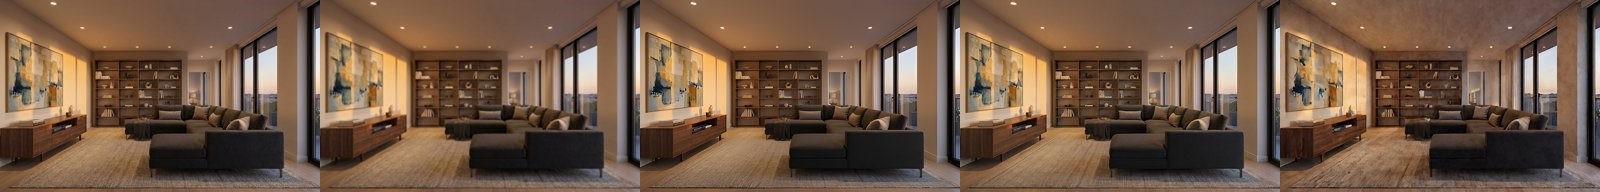

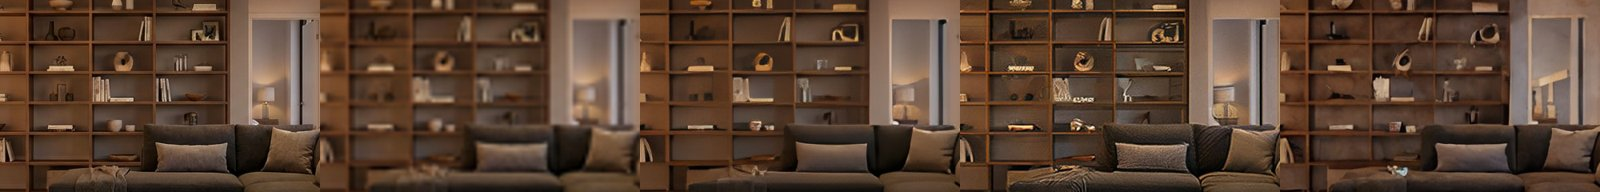

room 2: ground truth | A: Bicubic | B: Real-ESRGAN | C: SD x4 upscaler | D: Real-ESRGAN + SD refine


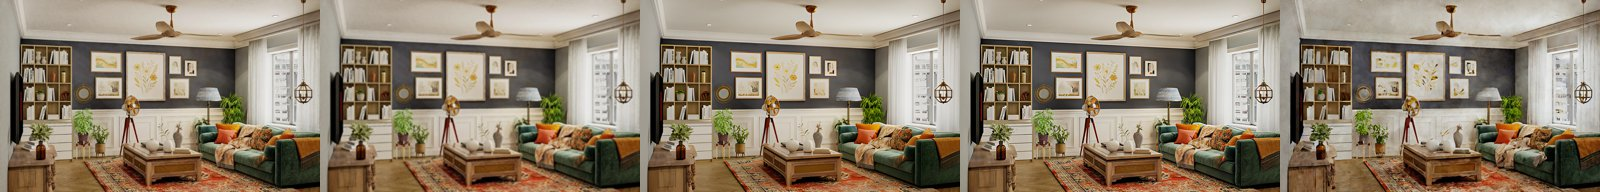

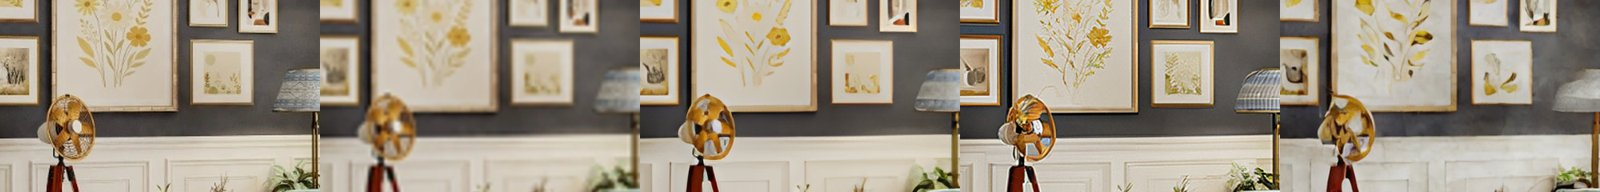

room 3: ground truth | A: Bicubic | B: Real-ESRGAN | C: SD x4 upscaler | D: Real-ESRGAN + SD refine


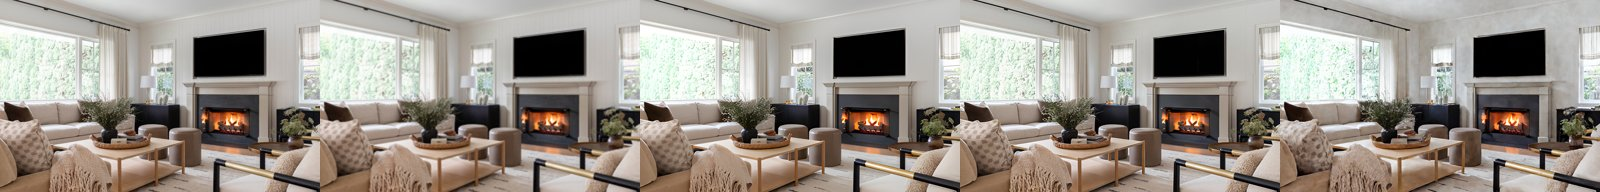

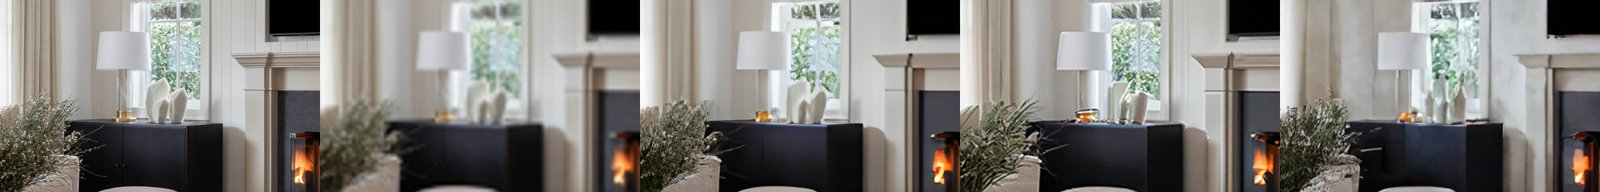

room 4: ground truth | A: Bicubic | B: Real-ESRGAN | C: SD x4 upscaler | D: Real-ESRGAN + SD refine


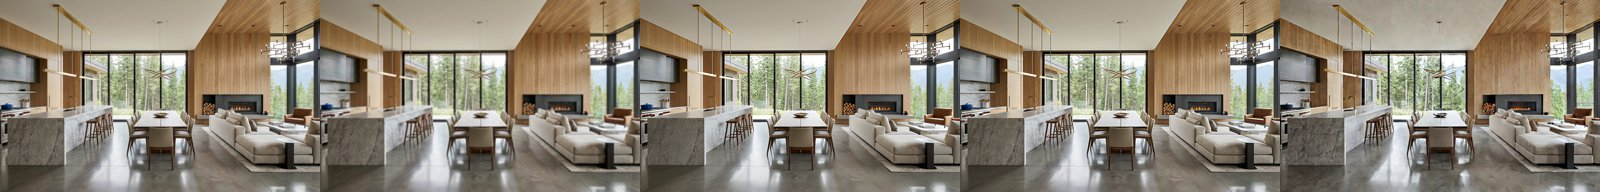

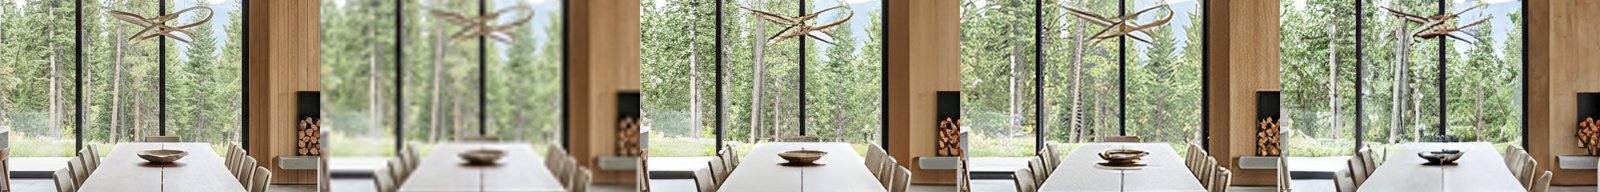

room 5: ground truth | A: Bicubic | B: Real-ESRGAN | C: SD x4 upscaler | D: Real-ESRGAN + SD refine


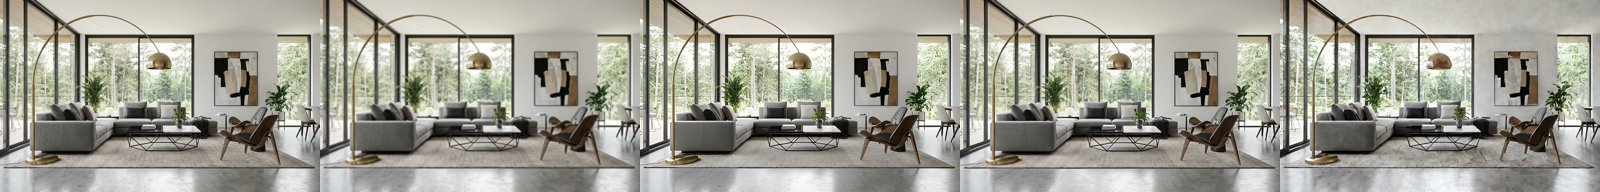

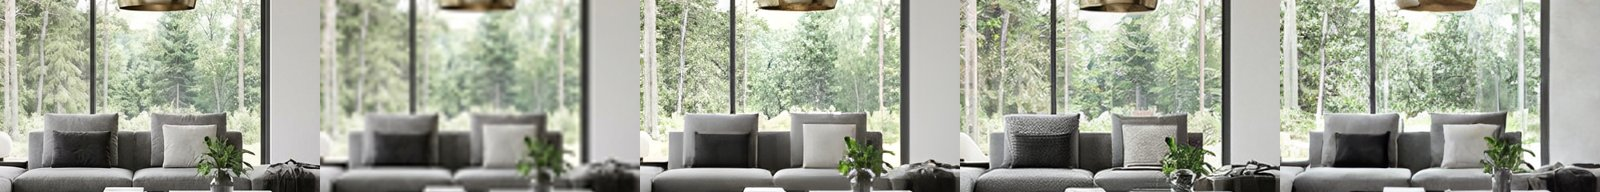

In [6]:
NAMES = list(METHODS)
CROP = (GT_W // 2 - 200, GT_H // 2 - 120, GT_W // 2 + 200, GT_H // 2 + 120)     # 400×240 at full size

def strip(imgs, w, h):
    row = Image.new("RGB", (w * len(imgs), h), "white")
    for i, im in enumerate(imgs): row.paste(im.resize((w, h)), (i * w, 0))
    return row

for n in gt:
    imgs = [gt[n]] + [results[(n, m)] for m in NAMES]
    full = strip(imgs, 320, 192)
    crops = strip([im.crop(CROP) for im in imgs], 400, 240)
    print(f"room {n}: ground truth | " + " | ".join(NAMES))
    show(full); show(crops)
    full.save(f"exp7_room{n}_full.jpg", quality=90); crops.save(f"exp7_room{n}_crops.jpg", quality=90)

## 7. Measure

In [7]:
import lpips
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.color import rgb2lab, deltaE_ciede2000

lp = lpips.LPIPS(net="alex", verbose=False).cuda()

def lpips_dist(a, b):
    ta, tb = to_tensor(a) * 2 - 1, to_tensor(b) * 2 - 1
    with torch.no_grad(): return float(lp(ta, tb))

def sharpness(img):
    return cv2.Laplacian(cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()

rows = []
for n in gt:
    g = np.array(gt[n]); g_sharp = sharpness(gt[n])
    for m in NAMES:
        r = np.array(results[(n, m)])
        rows.append({"room": n, "method": m,
                     "PSNR ↑": peak_signal_noise_ratio(g, r),
                     "SSIM ↑": structural_similarity(g, r, channel_axis=2),
                     "LPIPS ↓": lpips_dist(gt[n], results[(n, m)]),
                     "ΔE ↓": float(deltaE_ciede2000(rgb2lab(g), rgb2lab(r)).mean()),
                     "sharpness ratio (1 = real)": sharpness(results[(n, m)]) / g_sharp})

df = pd.DataFrame(rows).merge(pd.DataFrame(cost), on=["room", "method"])
summary = df.groupby("method").mean(numeric_only=True).drop(columns="room").reindex(NAMES)
display(summary.round(3))
display(df.pivot_table(index="room", columns="method", values="LPIPS ↓").reindex(columns=NAMES).round(3))

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:05<00:00, 44.8MB/s]


,PSNR ↑,SSIM ↑,LPIPS ↓,ΔE ↓,sharpness ratio (1 = real),sec/image,peak GB
method,,,,,,,
A: Bicubic,25.226,0.744,0.439,2.821,0.013,0.012,3.988
B: Real-ESRGAN,24.601,0.744,0.205,3.635,0.518,2.032,4.492
C: SD x4 upscaler,22.511,0.645,0.222,4.691,0.806,25.415,7.123
D: Real-ESRGAN + SD refine,21.786,0.648,0.279,5.605,0.405,10.235,6.387


method,A: Bicubic,B: Real-ESRGAN,C: SD x4 upscaler,D: Real-ESRGAN + SD refine
room,,,,
1,0.418,0.206,0.193,0.304
2,0.371,0.183,0.200,0.246
3,0.443,0.232,0.233,0.296
4,0.461,0.188,0.237,0.266
5,0.500,0.215,0.244,0.283


## 8. Chart

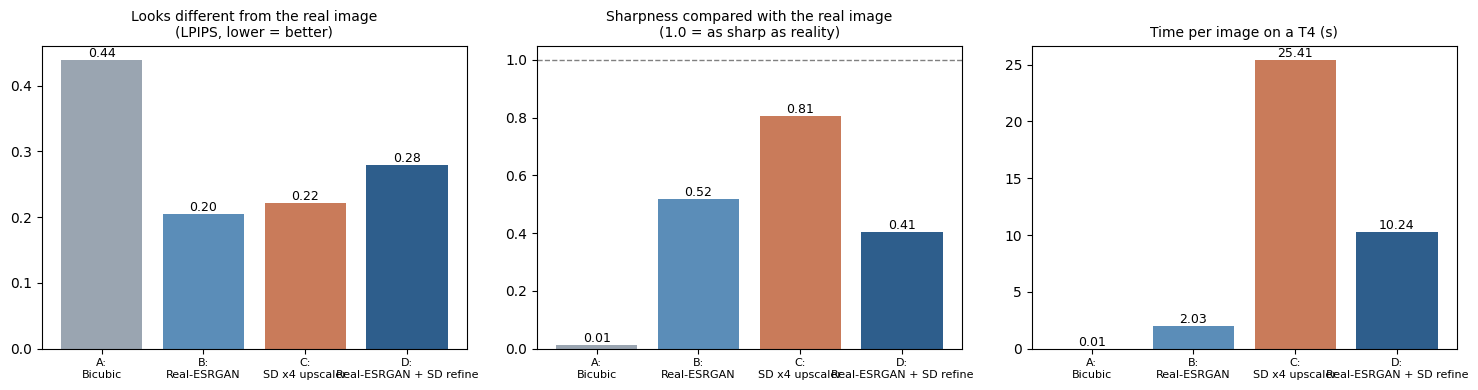

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#9AA5B1", "#5B8DB8", "#C97B5A", "#2E5E8C"]
labels = [m.replace(": ", ":\n") for m in NAMES]
for ax, col, title in zip(axes, ["LPIPS ↓", "sharpness ratio (1 = real)", "sec/image"],
                          ["Looks different from the real image\n(LPIPS, lower = better)",
                           "Sharpness compared with the real image\n(1.0 = as sharp as reality)",
                           "Time per image on a T4 (s)"]):
    ax.bar(labels, summary[col], color=colors)
    for i, v in enumerate(summary[col]): ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", labelsize=8)
axes[1].axhline(1.0, color="gray", ls="--", lw=1)
plt.tight_layout(); plt.savefig("exp7_upscaling.png", dpi=150); plt.show()

**What I saw.**
- **A (bicubic):** blurry everywhere (sharpness ratio 0.01), small objects on shelves cannot be recognised. Still, it has the **highest PSNR (25.2)**, because PSNR rewards staying close to the average pixel value and treats blur as safe.
- **B (Real-ESRGAN):** the best overall: best LPIPS (0.205) and SSIM (0.744, tied with bicubic), in 2 s per image with 4.5 GB. Edges are clean and nothing was invented, but fine details look slightly "painted" and smoothed (sharpness ratio 0.52).
- **C (SD x4 upscaler):** the sharpest result (0.81), and close to B in LPIPS (0.222; best in one room), but it **invents details**: a knitted texture on plain cushions, a new golden object next to white sculptures, changed shapes of vases and flowers in paintings. It is also 12× slower than B (25 s) and needs 7.1 GB.
- **D (Real-ESRGAN + SD refine):** the worst on every quality metric (LPIPS 0.279, ΔE 5.6). In all five rooms it added a **plaster-like texture to plain walls and ceilings**, changed small objects (sculptures became bottles) and changed paintings.

**Result.** For keeping a design, Real-ESRGAN is the best default upscaler: the most faithful, fast and cheap. Diffusion-based upscaling adds sharpness but also adds things that were not in the design, so it should be an explicit "creative" option, not the default. None of the metrics caught the invented details: my guess that a sharpness ratio above 1 would reveal invented texture was wrong (no method reached the real image's sharpness), and PSNR even ranked the blurry bicubic result first. The zoomed crops were needed to see what changed, the same lesson as Experiment 6.

**Limits.** The low-resolution inputs were made by shrinking real photos with bicubic resizing; real renders can have other kinds of blur and noise. Five rooms and one seed. PSNR and SSIM reward closeness to the original pixels, so they punish any added detail, even a plausible one; LPIPS and the crops show the other side. The SD x4 upscaler and the refine step were run with one prompt and one setting (strength 0.25).

## Download

In [9]:
df.to_csv("exp7_metrics.csv", index=False)
!zip -q exp7_results.zip exp7_*.jpg exp7_*.png exp7_metrics.csv
files.download("exp7_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>